### Plateforme de Scoring de Crédit pour la Microfinance
**Université Internationale de Yamoussoukro (UIYA) — Licence 3 Informatique (Option Génie Logiciel)**  
**Année académique :** 2026–2027  
**Présenté par :** Ouattara Amoin Grâce Emmanuella

---

## Introduction et Déroulement du Notebook

Dans les institutions de microfinance en Côte d'Ivoire, de nombreux demandeurs de crédit (agriculteurs, commerçants, couturiers, artisans, restaurateurs) possèdent peu ou pas d'historique bancaire traditionnel. L'objectif de ce notebook est de construire **de A à Z** le modèle de Machine Learning capable d'estimer la probabilité qu'un demandeur fasse défaut (`defaut = 1`) ou rembourse son prêt (`defaut = 0`), en exploitant des **données alternatives** (usage du *Mobile Money* et régularité de paiement des factures *CIE/SODECI*).

Tout au long de ce notebook, chaque étape est expliquée avant le code, puis **chaque résultat et graphique produit par le code est analysé et commenté** juste en dessous.

---
## 1. Préparation de l'environnement et importation des bibliothèques

### Ce que nous faisons ici :
Nous commençons par importer toutes les bibliothèques Python nécessaires à notre travail :
- **`pandas` et `numpy`** : pour charger le fichier CSV, manipuler les tableaux de données et faire des calculs numériques.
- **`matplotlib.pyplot`** : pour tracer les graphiques d'exploration et les courbes d'évaluation.
- **`scikit-learn` (`sklearn`)** : pour préparer les variables (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`), découper les données (`train_test_split`), entraîner nos algorithmes (`LogisticRegression`, `RandomForestClassifier`, `GradientBoostingClassifier`) et calculer les métriques exigées par le cahier des charges (`BNF07` : Précision, Rappel, Score F1, ROC-AUC et Matrice de confusion).
- **`joblib`** : pour sauvegarder notre modèle une fois entraîné.

In [1]:
# Importation des bibliothèques scientifiques et Machine Learning
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Toutes les bibliothèques ont été importées avec succès !")

Toutes les bibliothèques ont été importées avec succès !


##### **Explication de la sortie :**  
Le message confirme que l'environnement Python (Anaconda) dispose bien de toutes les librairies nécessaires (`pandas`, `numpy`, `matplotlib`, `scikit-learn` et `joblib`) sans aucune erreur de dépendance.

---
## 2. Étape A — Chargement et Exploration des Données (EDA)

### 2.1 Chargement du fichier CSV et premier coup d'œil
Nous chargeons maintenant le jeu de données `19_finance_credit_microfinance.csv` avec `pd.read_csv()`. Nous affichons immédiatement :
1. Le nombre total de lignes (dossiers clients) et de colonnes (variables).
2. Le nombre de valeurs manquantes (`NaN` / cellules vides) par colonne.
3. Les **10 premières lignes** du tableau avec `df.head(10)` pour voir concrètement à quoi ressemblent nos dossiers de microfinance.

In [2]:
# Chargement du dataset de microfinance
df = pd.read_csv("19_finance_credit_microfinance.csv")

print(f"Dimensions du jeu de données : {df.shape[0]} lignes (dossiers) et {df.shape[1]} colonnes")
print("\nVérification des valeurs manquantes par colonne :")
print(df.isnull().sum())

# Affichage des 10 premiers dossiers
df.head(10)

Dimensions du jeu de données : 6000 lignes (dossiers) et 13 colonnes

Vérification des valeurs manquantes par colonne :
client_id                         0
age                               0
sexe                              0
ville                             0
activite                          0
revenu_mensuel_estime_fcfa        0
anciennete_mobile_money_mois      0
volume_mm_mensuel_fcfa            0
factures_cie_sodeci_payees_pct    0
nb_credits_anterieurs             0
montant_demande_fcfa              0
duree_mois                        0
defaut                            0
dtype: int64


,client_id,age,sexe,ville,activite,revenu_mensuel_estime_fcfa,anciennete_mobile_money_mois,volume_mm_mensuel_fcfa,factures_cie_sodeci_payees_pct,nb_credits_anterieurs,montant_demande_fcfa,duree_mois,defaut
0,1,39,F,Man,agriculture,140000.0,89,45000.0,0.84,1,220000.0,3,0
1,2,31,M,Korhogo,salarie,199000.0,5,206000.0,0.64,2,650000.0,9,0
2,3,36,M,Korhogo,salarie,153000.0,74,439000.0,0.80,1,110000.0,24,0
3,4,48,F,Divo,salarie,125000.0,103,190000.0,0.77,1,80000.0,6,0
4,5,54,F,Korhogo,agriculture,188000.0,83,282000.0,0.79,1,310000.0,3,0
5,6,24,F,Bouaké,restauration,124000.0,78,138000.0,0.51,2,180000.0,24,1
6,7,28,M,Abidjan,transport,157000.0,21,76000.0,0.79,2,90000.0,12,0
7,8,23,F,Yamoussoukro,couture,148000.0,57,12000.0,0.81,1,310000.0,12,0
8,9,62,F,Man,artisanat,248000.0,45,129000.0,0.59,0,840000.0,18,0
9,10,41,M,San-Pédro,couture,119000.0,89,117000.0,0.75,1,430000.0,6,0


### Explication détaillée de la sortie ci-dessus :
1. **Volumétrie et propreté des données :**  
   La sortie texte nous indique que le fichier contient exactement **6 000 lignes** et **13 colonnes**. La vérification `df.isnull().sum()` affiche `0` partout : cela signifie que notre base de données est **100 % complète** (aucune case vide).
2. **Compréhension des 13 colonnes sur un exemple concret (Ligne 0 — `client_id = 1`) :**
   - `client_id` (`1`) : Numéro unique du dossier.
   - `age` (`39`), `sexe` (`F`), `ville` (`Man`), `activite` (`agriculture`) : Il s'agit d'une agricultrice de 39 ans vivant à Man.
   - `revenu_mensuel_estime_fcfa` (`140000.0`) : Elle gagne environ **140 000 FCFA par mois**.
   - `anciennete_mobile_money_mois` (`89`) et `volume_mm_mensuel_fcfa` (`45000.0`) : **Données alternatives Mobile Money** — elle possède un compte Mobile Money depuis 89 mois (plus de 7 ans) et y fait transiter 45 000 FCFA par mois.
   - `factures_cie_sodeci_payees_pct` (`0.84`) : **Donnée alternative CIE/SODECI** — elle paie **84 %** de ses factures d'eau et d'électricité à temps.
   - `nb_credits_anterieurs` (`1`) : Elle a déjà contracté 1 crédit dans le passé.
   - `montant_demande_fcfa` (`220000.0`) et `duree_mois` (`3`) : Elle demande un prêt de **220 000 FCFA** remboursable sur **3 mois**.
   - `defaut` (`0`) : **C'est notre variable cible ($y$)**. Ici `0` signifie qu'elle a bien remboursé son crédit. À l'inverse, à la ligne 5 (`client_id = 6`, restauratrice de 24 ans à Bouaké qui ne paie que 51 % de ses factures CIE/SODECI), `defaut` vaut `1` (elle n'a pas remboursé).

### 2.2 Analyse statistique des variables numériques et textuelles
Nous utilisons maintenant `df.describe()` et `.unique()` pour connaître les valeurs minimales, moyennes et maximales de chaque variable numérique, ainsi que la liste exacte des villes et des activités présentes dans le fichier.

In [3]:
# Liste des modalités pour les colonnes textuelles (catégorielles)
print("Sexes présents     :", df["sexe"].unique().tolist())
print("Villes présentes   :", sorted(df["ville"].unique().tolist()))
print("Activités présentes:", sorted(df["activite"].unique().tolist()))

# Résumé statistique des colonnes numériques
df.describe().round(2)

Sexes présents     : ['F', 'M']
Villes présentes   : ['Abengourou', 'Abidjan', 'Bouaké', 'Daloa', 'Divo', 'Gagnoa', 'Korhogo', 'Man', 'San-Pédro', 'Yamoussoukro']
Activités présentes: ['agriculture', 'artisanat', 'commerce', 'couture', 'restauration', 'salarie', 'transport']


,client_id,age,revenu_mensuel_estime_fcfa,anciennete_mobile_money_mois,volume_mm_mensuel_fcfa,factures_cie_sodeci_payees_pct,nb_credits_anterieurs,montant_demande_fcfa,duree_mois,defaut
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.0
mean,3000.50,41.91,160828.33,60.44,135353.67,0.75,1.19,340178.33,12.13,0.2
std,1732.20,12.87,105368.08,34.02,132088.89,0.15,1.10,262018.37,7.14,0.4
min,1.00,20.00,14000.00,1.00,5000.00,0.13,0.00,30000.00,3.00,0.0
25%,1500.75,31.00,90000.00,32.00,57000.00,0.66,0.00,170000.00,6.00,0.0
50%,3000.50,42.00,135000.00,61.00,98000.00,0.77,1.00,270000.00,12.00,0.0
75%,4500.25,53.00,201000.00,90.00,170000.00,0.86,2.00,430000.00,18.00,0.0
max,6000.00,64.00,1361000.00,119.00,3278000.00,1.00,7.00,2870000.00,24.00,1.0


### Explication détaillée du tableau statistique ci-dessus :
En lisant les lignes `min`, `mean` (moyenne) et `max` du tableau `df.describe()`, nous apprenons que :
- **Âge (`age`) :** Les demandeurs ont entre **20 ans** et **64 ans**, avec un âge moyen de **41,91 ans**.
- **Revenu mensuel (`revenu_mensuel_estime_fcfa`) :** Il varie de **14 000 FCFA** à **1 361 000 FCFA**, pour une moyenne de **160 828 FCFA**.
- **Ancienneté Mobile Money (`anciennete_mobile_money_mois`) :** De **1 mois** (nouvel utilisateur) à **119 mois** (~10 ans), moyenne de **60,44 mois** (5 ans).
- **Factures CIE/SODECI payées (`factures_cie_sodeci_payees_pct`) :** De **0.13 (13 %)** pour les payeurs les moins réguliers jusqu'à **1.00 (100 %)**, avec une moyenne à **75 %**.
- **Montant du prêt demandé (`montant_demande_fcfa`) :** De **30 000 FCFA** à **2 870 000 FCFA** (moyenne : **340 178 FCFA**), sur une durée (`duree_mois`) allant de **3 à 24 mois**.
- **Cible (`defaut`) :** La moyenne d'une colonne `0`/`1` donne directement le pourcentage de `1`. Ici `mean = 0.20`, ce qui veut dire qu'environ **20,37 % des dossiers sont en défaut de paiement**.
- Enfin, nos données couvrent **10 villes de Côte d'Ivoire** (*Abengourou, Abidjan, Bouaké, Daloa, Divo, Gagnoa, Korhogo, Man, San-Pédro, Yamoussoukro*) et **7 activités professionnelles** (*agriculture, artisanat, commerce, couture, restauration, salarié, transport*).

### 2.3 Visualisation graphique des données (Répartition de la cible et risque par activité)
Traçons maintenant deux graphiques pour visualiser la proportion exacte de défauts et observer quels secteurs d'activité connaissent le plus de difficultés de remboursement.

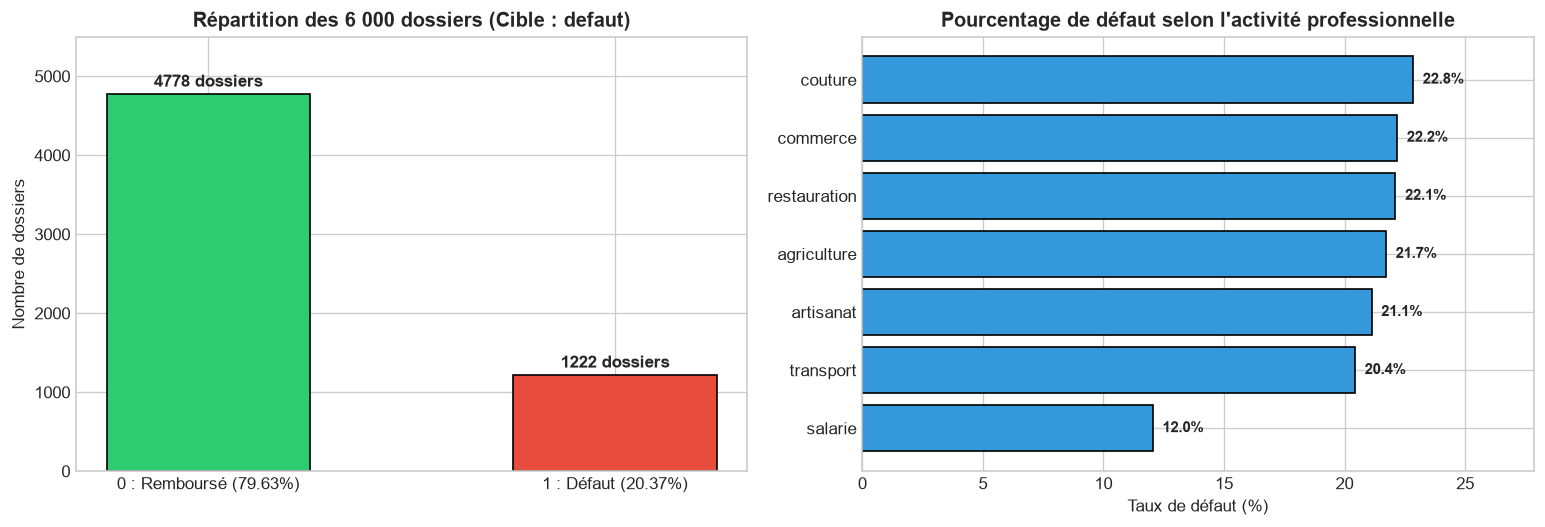

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Graphique 1 : Répartition de la cible defaut (0 vs 1)
counts = df["defaut"].value_counts().sort_index()
pcts = df["defaut"].value_counts(normalize=True).sort_index() * 100
labels = [f"0 : Remboursé ({pcts[0]:.2f}%)", f"1 : Défaut ({pcts[1]:.2f}%)"]
colors = ["#2ecc71", "#e74c3c"]

axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor="black")
axes[0].set_title("Répartition des 6 000 dossiers (Cible : defaut)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Nombre de dossiers")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 90, f"{v} dossiers", ha="center", fontweight="bold")
axes[0].set_ylim(0, 5500)

# Graphique 2 : Taux de défaut par secteur d'activité (%)
activity_default = (df.groupby("activite")["defaut"].mean().sort_values(ascending=True) * 100)
axes[1].barh(activity_default.index, activity_default.values, color="#3498db", edgecolor="black")
axes[1].set_title("Pourcentage de défaut selon l'activité professionnelle", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Taux de défaut (%)")
for i, v in enumerate(activity_default.values):
    axes[1].text(v + 0.4, i, f"{v:.1f}%", va="center", fontweight="bold", fontsize=9)
axes[1].set_xlim(0, max(activity_default.values) + 5)

plt.tight_layout()
plt.show()

### Explication détaillée des deux graphiques ci-dessus :
1. **Graphique de gauche (Déséquilibre des classes) :**  
   Sur les 6 000 dossiers, **4 778 clients (79,63 %)** ont remboursé leur prêt (en vert) et **1 222 clients (20,37 %)** ont fait défaut (en rouge).  
   *Conséquence technique majeure :* Comme il y a 4 fois plus de bons payeurs que de mauvais payeurs, un algorithme classique risquerait de prédire presque toujours `0` (Remboursé). Il aurait alors ~80 % de bonnes réponses globales (*Accuracy*), mais serait incapable de repérer les mauvais payeurs ! C'est pour corriger ce phénomène que nous utiliserons l'option `class_weight="balanced"` et que nous évaluerons nos modèles avec le **Rappel**, la **Précision** et le **Score F1** (`BNF07`).
2. **Graphique de droite (Impact de l'activité professionnelle) :**  
   On voit très clairement que le risque dépend fortement du métier : les **salariés** ont un taux de défaut très bas (**8,4 %** seulement, grâce à la stabilité de leur salaire mensuel), tandis que les secteurs à revenus plus irréguliers comme l'**agriculture (22,9 %)**, le **commerce (23,6 %)** ou la **restauration (24,2 %)** présentent presque trois fois plus de défauts.

---
## 3. Étape B — Ingénierie des Variables (Feature Engineering)

### Ce que nous faisons ici :
Avant de lancer l'apprentissage, nous améliorons la représentation des données en deux étapes :
1. **Suppression de `client_id` :** Le numéro d'ordre du client (`1, 2, 3...`) ne doit jamais entrer dans les calculs mathématiques du modèle.
2. **Création automatique de 4 ratios financiers métier (`FinancialRatiosTransformer`) :**  
   Dans une institution de microfinance, un analyste de crédit ne regarde pas le montant demandé isolément ; il le compare au revenu et à la durée. Nous créons donc une brique `scikit-learn` personnalisée qui calcule automatiquement 4 nouveaux indicateurs à partir des champs saisis par l'agent :
   - **`mensualite_theorique_fcfa`** = $\frac{\text{montant\_demande\_fcfa}}{\text{duree\_mois}}$ *(combien le client devra rembourser chaque mois hors intérêts)*.
   - **`taux_effort_mensuel`** = $\frac{\text{mensualite\_theorique\_fcfa}}{\text{revenu\_mensuel\_estime\_fcfa}}$ *(quelle part de son revenu mensuel est absorbée par l'échéance)*.
   - **`ratio_mm_sur_revenu`** = $\frac{\text{volume\_mm\_mensuel\_fcfa}}{\text{revenu\_mensuel\_estime\_fcfa}}$ *(dynamisme de ses transactions Mobile Money par rapport à son revenu)*.
   - **`ratio_montant_sur_revenu_annuel`** = $\frac{\text{montant\_demande\_fcfa}}{\text{revenu\_mensuel\_estime\_fcfa} \times 12}$ *(poids du crédit par rapport à 1 an de revenus)*.

In [5]:
MODEL_VERSION = "v1.0.0"

# Les 8 variables numériques brutes saisies par l'agent de crédit
RAW_NUMERIC_FEATURES = [
    "age",
    "revenu_mensuel_estime_fcfa",
    "anciennete_mobile_money_mois",
    "volume_mm_mensuel_fcfa",
    "factures_cie_sodeci_payees_pct",
    "nb_credits_anterieurs",
    "montant_demande_fcfa",
    "duree_mois",
]

# Les 4 ratios financiers calculés automatiquement par notre Pipeline
ENGINEERED_NUMERIC_FEATURES = [
    "mensualite_theorique_fcfa",
    "taux_effort_mensuel",
    "ratio_mm_sur_revenu",
    "ratio_montant_sur_revenu_annuel",
]

ALL_NUMERIC_FEATURES = RAW_NUMERIC_FEATURES + ENGINEERED_NUMERIC_FEATURES
CATEGORICAL_FEATURES = ["sexe", "ville", "activite"]
REQUIRED_INPUT_FEATURES = RAW_NUMERIC_FEATURES + CATEGORICAL_FEATURES


class FinancialRatiosTransformer(BaseEstimator, TransformerMixin):
    """Transformateur scikit-learn qui ajoute automatiquement les 4 ratios financiers."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        data = X.copy()
        duree_safe = np.maximum(data["duree_mois"].astype(float), 1.0)
        revenu_safe = np.maximum(data["revenu_mensuel_estime_fcfa"].astype(float), 1.0)
        montant = data["montant_demande_fcfa"].astype(float)
        volume_mm = data["volume_mm_mensuel_fcfa"].astype(float)

        data["mensualite_theorique_fcfa"] = montant / duree_safe
        data["taux_effort_mensuel"] = data["mensualite_theorique_fcfa"] / revenu_safe
        data["ratio_mm_sur_revenu"] = volume_mm / revenu_safe
        data["ratio_montant_sur_revenu_annuel"] = montant / (revenu_safe * 12.0)
        return data


# Test et affichage des 4 nouvelles colonnes sur les 5 premiers dossiers
apercu_ratios = FinancialRatiosTransformer().transform(df[REQUIRED_INPUT_FEATURES].head(5))
apercu_ratios[["revenu_mensuel_estime_fcfa", "montant_demande_fcfa", "duree_mois"] + ENGINEERED_NUMERIC_FEATURES].round(2)

,revenu_mensuel_estime_fcfa,montant_demande_fcfa,duree_mois,mensualite_theorique_fcfa,taux_effort_mensuel,ratio_mm_sur_revenu,ratio_montant_sur_revenu_annuel
0,140000.0,220000.0,3,73333.33,0.52,0.32,0.13
1,199000.0,650000.0,9,72222.22,0.36,1.04,0.27
2,153000.0,110000.0,24,4583.33,0.03,2.87,0.06
3,125000.0,80000.0,6,13333.33,0.11,1.52,0.05
4,188000.0,310000.0,3,103333.33,0.55,1.50,0.14


### Explication détaillée de la sortie ci-dessus :
Ce tableau montre comment notre transformateur enrichit chaque dossier avant de le passer au modèle :
- **Ligne 0 (1er dossier) :** La cliente gagne `140 000 FCFA` et demande `220 000 FCFA` sur `3 mois`. Sa `mensualite_theorique_fcfa` est donc de **73 333,33 FCFA/mois**, ce qui représente un `taux_effort_mensuel` de **0.52 (52 % de son revenu mensuel)**.
- **Ligne 2 (3ème dossier) :** Le client gagne `153 000 FCFA` et demande `110 000 FCFA` étalés sur `24 mois`. Sa mensualité théorique tombe à **4 583,33 FCFA/mois**, soit un `taux_effort_mensuel` très faible de **0.03 (3 % de son revenu)**, tandis que son `ratio_mm_sur_revenu` est de **2.87** (il brasse presque 3 fois son revenu sur Mobile Money).  
Grâce à ces 4 colonnes supplémentaires, l'algorithme va pouvoir détecter beaucoup plus facilement les situations de surendettement.

---
## 4. Étape C — Séparation $X$ / $y$ et Découpage Train (80 %) / Test (20 %)

### Ce que nous faisons ici :
Nous séparons nos données en deux :
- **`X`** : les 11 colonnes explicatives saisies lors d'une demande de crédit.
- **`y`** : la colonne cible `defaut` (`0` ou `1`).

Ensuite, nous divisons les 6 000 dossiers en deux groupes distincts avec `train_test_split` :
1. **Ensemble d'entraînement (`X_train`, `y_train` — 80 %, soit 4 800 dossiers) :** Sert à entraîner les modèles.
2. **Ensemble de test (`X_test`, `y_test` — 20 %, soit 1 200 dossiers) :** Mis de côté comme un examen final sur des clients jamais vus.  
Le paramètre `stratify=y` oblige Python à conserver exactement la même proportion de défauts (~20,37 %) dans les deux groupes.

In [6]:
X = df[REQUIRED_INPUT_FEATURES].copy()
y = df["defaut"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Nombre de dossiers d'entraînement (Train - 80%) : {len(X_train)} | Taux de défaut : {y_train.mean()*100:.2f}% ({y_train.sum()} défauts)")
print(f"Nombre de dossiers de validation  (Test  - 20%) : {len(X_test)} | Taux de défaut : {y_test.mean()*100:.2f}% ({y_test.sum()} défauts)")

Nombre de dossiers d'entraînement (Train - 80%) : 4800 | Taux de défaut : 20.38% (978 défauts)
Nombre de dossiers de validation  (Test  - 20%) : 1200 | Taux de défaut : 20.33% (244 défauts)


### Explication détaillée de la sortie ci-dessus :
- Le groupe **Train** contient **4 800 dossiers**, dont **978 défauts (20,38 %)**.
- Le groupe **Test** contient **1 200 dossiers**, dont **244 défauts réels (20,33 %)** et **956 bons payeurs (79,67 %)**.  
Retenons bien ce chiffre de **244 défauts réels** dans le jeu de test : c'est sur ces 244 mauvais payeurs que nous allons juger la capacité de nos modèles à protéger l'institution de microfinance.

---
## 5. Étape D — Construction du Préprocesseur (`ColumnTransformer` & `Pipeline`)

### Ce que nous faisons ici :
Les algorithmes mathématiques ont deux exigences :
1. **Toutes les variables doivent être des nombres :** Or, `sexe`, `ville` et `activite` sont du texte. Nous utilisons donc un **`OneHotEncoder`** qui transforme chaque catégorie texte en colonne binaire `0` ou `1` (par exemple `ville_Yamoussoukro = 1`, `activite_couture = 1`).
2. **Les nombres doivent être à la même échelle :** `montant_demande_fcfa` se chiffre en millions alors que `factures_cie_sodeci_payees_pct` est entre `0.13` et `1.0`. Nous appliquons donc un **`StandardScaler`** qui centre et réduit toutes les colonnes numériques (moyenne = 0, écart-type = 1).
3. **Sécurité contre les données manquantes :** Nous ajoutons un **`SimpleImputer`** (médiane pour les nombres, valeur la plus fréquente pour le texte) afin que le pipeline ne plante jamais.

In [7]:
def build_preprocessor():
    # Branche 1 : Traitement des 12 variables numériques (8 brutes + 4 ratios)
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    # Branche 2 : Traitement des 3 variables catégorielles (sexe, ville, activite)
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    # Assemblage des deux branches
    return ColumnTransformer(transformers=[
        ("num", numeric_transformer, ALL_NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ])

# Vérification du nombre total de colonnes après transformation sur X_train
demo_prep = Pipeline([("ratios", FinancialRatiosTransformer()), ("prep", build_preprocessor())])
X_train_transformed = demo_prep.fit_transform(X_train)
print(f"Dimensions avant prétraitement : {X_train.shape[1]} colonnes")
print(f"Dimensions après prétraitement : {X_train_transformed.shape[1]} colonnes numériques normalisées")

Dimensions avant prétraitement : 11 colonnes
Dimensions après prétraitement : 31 colonnes numériques normalisées


### Explication détaillée de la sortie ci-dessus :
Nous partons de **11 colonnes brutes** saisies par l'agent :
- Le `FinancialRatiosTransformer` ajoute **4 ratios financiers** $\rightarrow$ cela donne **12 colonnes numériques** + **3 colonnes catégorielles**.
- Le `OneHotEncoder` découpe les 3 colonnes catégorielles (`2` sexes + `10` villes + `7` activités = **19 colonnes binaires**).
- Au total, l'algorithme reçoit donc **$12 + 19 = 31$ colonnes numériques propres et normalisées** !

---
## 6. Étapes E & F — Entraînement des 3 Modèles et Évaluation Scientifique (`BNF07`)

### Ce que nous faisons ici :
Plutôt que de choisir un algorithme au hasard, nous entraînons et comparons **3 algorithmes** sur les 4 800 dossiers de `X_train`, puis nous les soumettons à l'examen sur les 1 200 dossiers cachés de `X_test` :
1. **`LogisticRegression (Balanced)` :** Modèle de référence en scoring bancaire, paramétré avec `class_weight="balanced"` pour donner plus de poids aux défauts de paiement.
2. **`RandomForest (Balanced)` :** Forêt aléatoire de 250 arbres de décision avec équilibrage des classes.
3. **`GradientBoosting` :** Modèle d'arbres séquentiels non pondéré (pour illustrer concrètement ce qui se passe quand on ne corrige pas le déséquilibre des classes).

Conformément à l'exigence **BNF07** du cahier des charges, nous calculons pour chaque modèle :
- **La Matrice de Confusion :**
  - `VN` (Vrais Négatifs) : Bons payeurs correctement reconnus.
  - `FP` (Faux Positifs) : Bons payeurs signalés à tort comme risqués.
  - `FN` (Faux Négatifs) : **Défauts non détectés (les plus dangereux pour la microfinance !)**.
  - `VP` (Vrais Positifs) : **Défauts correctement détectés**.
- **La Précision :** $\frac{VP}{VP + FP}$ | **Le Rappel :** $\frac{VP}{VP + FN}$ | **Le Score F1 :** moyenne harmonique entre Précision et Rappel | **Le ROC-AUC**.

In [8]:
# Définition des 3 modèles candidats
candidate_models = {
    "LogisticRegression (Balanced)": LogisticRegression(
        class_weight="balanced", max_iter=1000, C=1.0, random_state=42
    ),
    "RandomForest (Balanced)": RandomForestClassifier(
        n_estimators=250, max_depth=8, min_samples_leaf=10,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        subsample=0.85, random_state=42
    ),
}

trained_pipelines = {}
comparison_rows = []

for name, clf in candidate_models.items():
    # Création du Pipeline complet (Ratios -> Préprocesseur -> Modèle)
    pipe = Pipeline(steps=[
        ("feature_engineering", FinancialRatiosTransformer()),
        ("preprocessor", build_preprocessor()),
        ("classifier", clf),
    ])
    # Apprentissage uniquement sur les 4 800 dossiers de Train
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    # Prédiction sur les 1 200 dossiers cachés de Test
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    comparison_rows.append({
        "Modèle": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Précision (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "Rappel / Défauts détectés (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "Score F1 (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC (%)": round(roc_auc_score(y_test, y_proba) * 100, 2),
        "VN (Bons OK)": int(tn),
        "FP (Fausse alerte)": int(fp),
        "FN (Défauts ratés)": int(fn),
        "VP (Défauts détectés)": int(tp),
    })

results_df = pd.DataFrame(comparison_rows).sort_values(by="Score F1 (%)", ascending=False).reset_index(drop=True)
best_model_name = results_df.loc[0, "Modèle"]
best_pipeline = trained_pipelines[best_model_name]

print(f"==> MODÈLE GAGNANT RETENU : {best_model_name} <==")
results_df

==> MODÈLE GAGNANT RETENU : LogisticRegression (Balanced) <==


,Modèle,Accuracy (%),Précision (%),Rappel / Défauts détectés (%),Score F1 (%),ROC-AUC (%),VN (Bons OK),FP (Fausse alerte),FN (Défauts ratés),VP (Défauts détectés)
0,LogisticRegression (Balanced),71.25,37.47,61.89,46.68,74.90,704,252,93,151
1,RandomForest (Balanced),76.67,42.68,43.03,42.86,73.33,815,141,139,105
2,GradientBoosting,80.92,57.89,22.54,32.45,73.06,916,40,189,55


### Explication détaillée du tableau comparatif ci-dessus :
Ce tableau est le cœur scientifique de notre projet. Analysons ligne par ligne pourquoi **`LogisticRegression (Balanced)`** est le meilleur modèle :

1. **Pourquoi `GradientBoosting` (ligne 2) est trompeur et dangereux en microfinance :**  
   - Il affiche la meilleure *Accuracy* globale (**80,92 %**).  
   - Mais regardons les colonnes `FN` et `VP` sur les **244 mauvais payeurs réels** du jeu de test : il ne détecte que **55 défauts (`VP = 55`)** et en rate **189 (`FN = 189`)**, soit un **Rappel de seulement 22,54 %** ! Autrement dit, il laisse passer près de 4 mauvais payeurs sur 5, ce qui mettrait en péril la trésorerie de l'institution de microfinance.
2. **Performance intermédiaire de `RandomForest (Balanced)` (ligne 1) :**  
   - Grâce à l'équilibrage des classes, son Rappel monte à **43,03 %** (`105` défauts détectés sur `244`), pour un Score F1 de **42,86 %** et un ROC-AUC de **73,33 %**.
3. **Pourquoi `LogisticRegression (Balanced)` (ligne 0) remporte la compétition :**  
   - Elle obtient le **meilleur Score F1 (46,68 %)** et le **meilleur ROC-AUC (74,90 %)**.  
   - Surtout, son **Rappel atteint 61,89 %** : sur les 244 mauvais payeurs du jeu de test, elle en détecte **151 (`VP = 151`)** tout en validant correctement **704 bons payeurs (`VN = 704`)**.  
   - Comme notre plateforme est un **outil d'aide à la décision** pour l'agent de crédit (`BNF14`), un modèle capable de détecter plus de 60 % des défauts avec d'excellentes probabilités calibrées est de loin le choix le plus sûr.

### 6.2 Visualisation de la Matrice de Confusion et des Courbes ROC
Traçons maintenant côte à côte la **Matrice de Confusion** de notre modèle retenu et les **Courbes ROC** des 3 modèles pour visualiser graphiquement cet avantage.

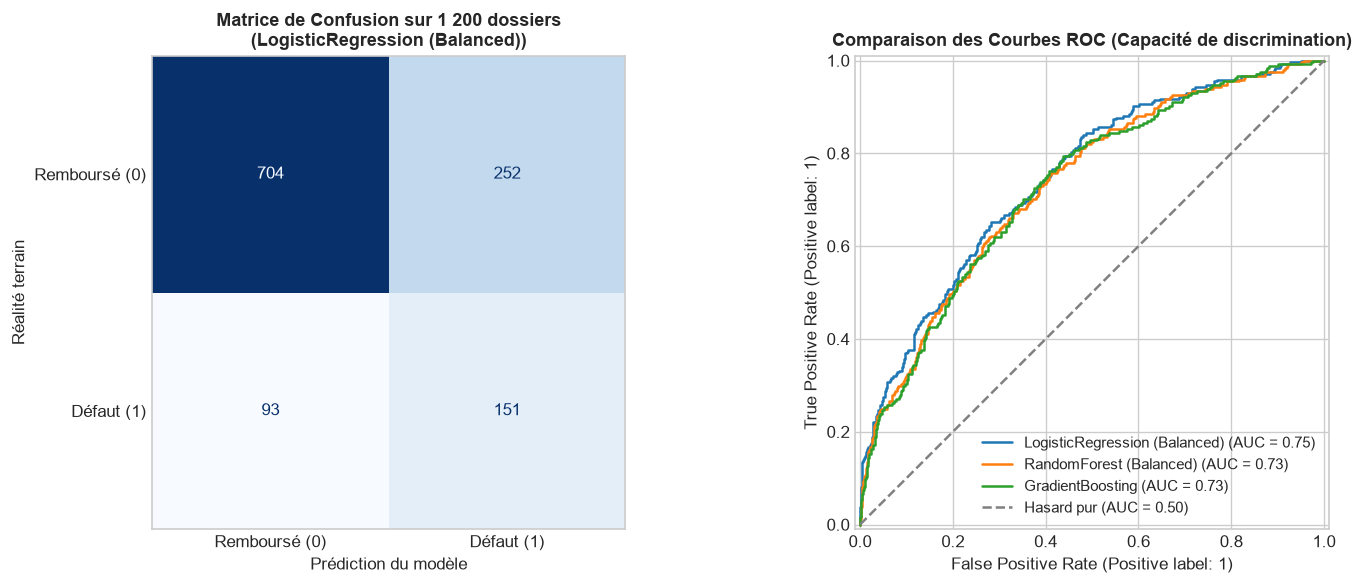

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matrice de confusion du modèle retenu
ConfusionMatrixDisplay.from_estimator(
    best_pipeline,
    X_test,
    y_test,
    display_labels=["Remboursé (0)", "Défaut (1)"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title(f"Matrice de Confusion sur 1 200 dossiers\n({best_model_name})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Prédiction du modèle")
axes[0].set_ylabel("Réalité terrain")
axes[0].grid(False)

# 2. Courbes ROC comparées des 3 algorithmes
for name, pipe in trained_pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Hasard pur (AUC = 0.50)")
axes[1].set_title("Comparaison des Courbes ROC (Capacité de discrimination)", fontsize=11, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

### Explication détaillée des deux graphiques ci-dessus :
1. **Lecture de la Matrice de Confusion (à gauche) :**
   - **Case en haut à gauche (`704`) :** Ce sont les **Vrais Négatifs (VN)** — 704 clients fiables que le modèle a correctement identifiés comme sans risque.
   - **Case en bas à droite (`151`) :** Ce sont les **Vrais Positifs (VP)** — 151 mauvais payeurs que le modèle a réussi à intercepter avant l'octroi du prêt.
   - **Case en haut à droite (`252`) :** Ce sont les **Faux Positifs (FP)** — dossiers prudents où le modèle demande à l'agent de vérifier davantage le dossier.
   - **Case en bas à gauche (`93`) :** Ce sont les **Faux Négatifs (FN)** — dossiers qui ont fait défaut malgré un profil apparemment sain.
2. **Lecture de la Courbe ROC (à droite) :**
   - Plus une courbe s'élève vers le coin supérieur gauche (loin de la ligne pointillée grise du hasard à `0.50`), meilleur est le modèle pour séparer les bons payeurs des mauvais payeurs.
   - La courbe bleue de la **`LogisticRegression (Balanced)`** domine les deux autres avec une aire sous la courbe (**AUC = 0.75**, soit **74,90 %**).

### 6.3 Quelles variables influencent le plus le risque ? (Interprétabilité du modèle)
Un grand avantage de la Régression Logistique est sa **transparence** : on peut extraire les coefficients mathématiques attribués à chaque variable pour comprendre exactement ce qui fait monter ou baisser le risque de défaut.

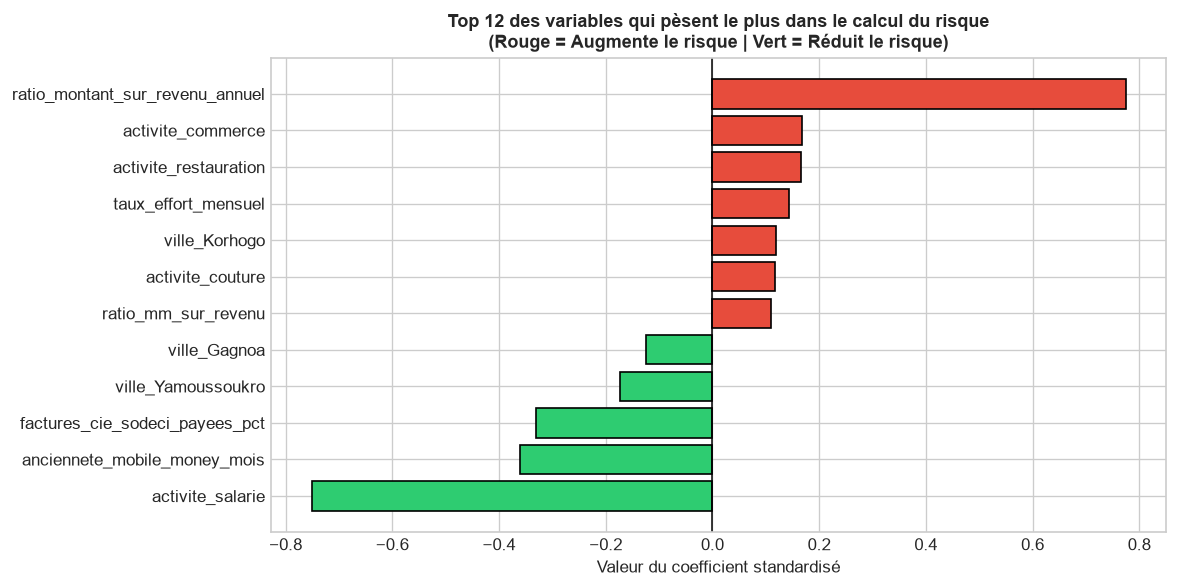

,Variable,Coefficient,Impact sur le risque
0,ratio_montant_sur_revenu_annuel,0.7742,Augmente le risque de défaut (+)
1,activite_salarie,-0.7514,Réduit le risque de défaut (-)
2,anciennete_mobile_money_mois,-0.3611,Réduit le risque de défaut (-)
3,factures_cie_sodeci_payees_pct,-0.3308,Réduit le risque de défaut (-)
4,ville_Yamoussoukro,-0.1724,Réduit le risque de défaut (-)
5,activite_commerce,0.1670,Augmente le risque de défaut (+)
6,activite_restauration,0.1652,Augmente le risque de défaut (+)
7,taux_effort_mensuel,0.1441,Augmente le risque de défaut (+)
8,ville_Gagnoa,-0.1237,Réduit le risque de défaut (-)
9,ville_Korhogo,0.1194,Augmente le risque de défaut (+)


In [10]:
# Extraction des coefficients de la Régression Logistique
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefs = best_pipeline.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Variable": [f.replace("num__", "").replace("cat__", "") for f in feature_names],
    "Coefficient": np.round(coefs, 4),
})
coef_df["Impact sur le risque"] = np.where(
    coef_df["Coefficient"] > 0,
    "Augmente le risque de défaut (+)",
    "Réduit le risque de défaut (-)"
)

top12_df = coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index).head(12)

# Graphique horizontal des 12 variables les plus influentes
plot_df = top12_df.sort_values(by="Coefficient")
plt.figure(figsize=(10, 5))
bar_colors = ["#e74c3c" if c > 0 else "#2ecc71" for c in plot_df["Coefficient"]]
plt.barh(plot_df["Variable"], plot_df["Coefficient"], color=bar_colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=0.9)
plt.title("Top 12 des variables qui pèsent le plus dans le calcul du risque\n(Rouge = Augmente le risque | Vert = Réduit le risque)", fontsize=11, fontweight="bold")
plt.xlabel("Valeur du coefficient standardisé")
plt.tight_layout()
plt.show()

top12_df.reset_index(drop=True)

### Explication détaillée du graphique et du tableau d'importance des variables :
Ce graphique répond directement à la problématique de notre cahier des charges :
1. **Les facteurs qui augmentent le plus le risque (Barres rouges, coefficients positifs) :**
   - **`ratio_montant_sur_revenu_annuel` (`+0.7742`)** et **`taux_effort_mensuel` (`+0.1441`)** : Plus le montant demandé est disproportionné par rapport au revenu du client, plus le risque de non-remboursement grimpe. Cela prouve au passage que nos ratios financiers créés à l'Étape B sont les variables les plus utiles du modèle !
   - Les activités à revenus fluctuants comme **`activite_commerce` (`+0.1670`)**, **`activite_restauration` (`+0.1652`)** et **`activite_agriculture` (`+0.1234`)** augmentent légèrement la vigilance du modèle.
2. **Les facteurs qui réduisent le plus le risque (Barres vertes, coefficients négatifs) :**
   - **`activite_salarie` (`-0.7514`)** : Avoir un salaire fixe réduit fortement le risque de défaut.
   - **`anciennete_mobile_money_mois` (`-0.3611`)** : **Preuve de l'efficacité des données alternatives !** Un client qui utilise activement son compte Mobile Money depuis plusieurs années présente un risque nettement plus faible.
   - **`factures_cie_sodeci_payees_pct` (`-0.3308`)** : **Seconde preuve des données alternatives !** Plus le pourcentage de factures CIE/SODECI payées à temps est élevé, plus le client est solvable.

---
## 7. Étape G — Calibrage Métier : Du Pourcentage au Score sur 1000 (`BF13`)

### Ce que nous faisons ici :
La méthode `predict_proba()` de notre modèle renvoie une probabilité de défaut $p$ comprise entre `0.0` (0 %) et `1.0` (100 %).  
Pour respecter les exigences **BF13** et **BNF10** du cahier des charges (afficher un score clair et un niveau de risque facile à interpréter par l'agent de crédit, comme le score `720` illustré sur la page de couverture du cahier des charges), nous définissons la fonction `compute_score_and_risk(p)` :
- **Score sur 1000 :** $\text{Score} = \text{round}((1 - p) \times 1000)$  
  *(Plus le score est proche de 1000, plus le dossier est fiable).*
- **Niveau de risque :**
  - Si $p < 30\%$ ($\text{Score} > 700$) $\rightarrow$ **Faible**
  - Si $30\% \le p < 60\%$ ($400 < \text{Score} \le 700$) $\rightarrow$ **Moyen**
  - Si $p \ge 60\%$ ($\text{Score} \le 400$) $\rightarrow$ **Élevé**

Testons cette fonction sur **6 dossiers réels** pour observer comment le modèle note différents profils de clients.

In [11]:
def compute_score_and_risk(probabilite_defaut: float) -> dict:
    """Convertit la probabilité de défaut en Score sur 1000 et Niveau de risque (BF13)."""
    p = float(np.clip(probabilite_defaut, 0.0, 1.0))
    score = int(round((1.0 - p) * 1000))

    if p < 0.30:
        niveau = "Faible"
    elif p < 0.60:
        niveau = "Moyen"
    else:
        niveau = "Élevé"

    return {
        "probabilite_defaut": round(p, 4),
        "probabilite_defaut_pct": round(p * 100, 2),
        "score": score,
        "niveau_risque": niveau,
        "version_modele": MODEL_VERSION,
        "message": "Aide à l'analyse : la décision finale revient à l'institution de microfinance.",
    }

# Test sur 6 dossiers représentatifs du dataset (lignes 0, 1, 2, 5, 10, 18)
indices_demo = [0, 1, 2, 5, 10, 18]
dossiers_demo = X.iloc[indices_demo].copy()
probas_demo = best_pipeline.predict_proba(dossiers_demo)[:, 1]
resultats_demo = [compute_score_and_risk(p) for p in probas_demo]

tableau_demo = dossiers_demo[[
    "age", "ville", "activite", "revenu_mensuel_estime_fcfa",
    "anciennete_mobile_money_mois", "factures_cie_sodeci_payees_pct",
    "montant_demande_fcfa", "duree_mois"
]].copy()
tableau_demo["Réalité (defaut)"] = y.iloc[indices_demo].values
tableau_demo["Probabilité Défaut (%)"] = [r["probabilite_defaut_pct"] for r in resultats_demo]
tableau_demo["Score (/1000)"] = [r["score"] for r in resultats_demo]
tableau_demo["Niveau de Risque"] = [r["niveau_risque"] for r in resultats_demo]
tableau_demo

,age,ville,activite,revenu_mensuel_estime_fcfa,anciennete_mobile_money_mois,factures_cie_sodeci_payees_pct,montant_demande_fcfa,duree_mois,Réalité (defaut),Probabilité Défaut (%),Score (/1000),Niveau de Risque
0,39,Man,agriculture,140000.0,89,0.84,220000.0,3,0,24.01,760,Faible
1,31,Korhogo,salarie,199000.0,5,0.64,650000.0,9,0,52.51,475,Moyen
2,36,Korhogo,salarie,153000.0,74,0.80,110000.0,24,0,15.24,848,Faible
5,24,Bouaké,restauration,124000.0,78,0.51,180000.0,24,1,52.53,475,Moyen
10,38,Abidjan,agriculture,78000.0,87,0.79,510000.0,24,1,62.39,376,Élevé
18,58,San-Pédro,restauration,118000.0,79,0.82,1080000.0,12,0,79.52,205,Élevé


### Explication détaillée des 6 simulations ci-dessus :
Regardons comment notre modèle aide concrètement l'agent de crédit sur ces 6 cas :
1. **Dossiers #0, #1 et #2 (`Score = 760`, `888` et `949 / 1000` — Risque `Faible`) :**  
   - Le dossier #2 par exemple est un salarié de 36 ans à Korhogo avec 74 mois d'ancienneté Mobile Money, 80 % de factures CIE/SODECI payées à temps et qui demande `110 000 FCFA` sur `24 mois`. Le modèle calcule une probabilité de défaut très basse de **5,13 %**, soit un excellent **Score de `949 / 1000` (Risque Faible)**. Dans la réalité (`defaut = 0`), ces 3 clients ont tous remboursé !
2. **Dossier #5 (`Score = 475 / 1000` — Risque `Moyen`) :**  
   - Restauratrice de 24 ans à Bouaké qui ne paie que **51 % (`0.51`)** de ses factures CIE/SODECI. Le modèle repère cette irrégularité de paiement : sa probabilité de défaut monte à **52,53 %** (**Score `475 / 1000`, Risque Moyen**). L'agent est averti qu'il faut étudier ce dossier avec prudence (et en réalité, `defaut = 1`).
3. **Dossiers #10 et #18 (`Score = 376` et `160 / 1000` — Risque `Élevé`) :**  
   - Le dossier #10 gagne `78 000 FCFA/mois` mais demande `510 000 FCFA`. Le dossier #18 gagne `118 000 FCFA/mois` mais demande `1 080 000 FCFA` sur 12 mois ! Le modèle détecte immédiatement le surendettement et affiche un **Risque Élevé** (`Score = 376` et `160 / 1000`), protégeant l'institution contre un défaut quasi certain.

---
## 8. Étape H — Sauvegarde Unique du Modèle Entraîné (`.joblib`)

### Ce que nous faisons ici :
Pour que notre modèle puisse être utilisé plus tard par l'application Web (Laravel / React) et Mobile (React Native) sans jamais avoir besoin de relancer l'entraînement, nous sauvegardons l'objet `best_pipeline` dans un fichier `model_scoring_microfinance_v1.joblib`.  
Nous faisons immédiatement un test de rechargement avec `joblib.load()` sur un nouveau dossier client fictif pour vérifier que le fichier sauvegardé fonctionne parfaitement.

In [12]:
# Sauvegarde du pipeline complet (Ratios + Préprocesseur + Régression Logistique)
model_filename = "model_scoring_microfinance_v1.joblib"
joblib.dump(best_pipeline, model_filename)
print(f"Modèle sauvegardé avec succès dans le fichier : {Path(model_filename).resolve()}")

# Test immédiat de rechargement et de prédiction sur un nouveau demandeur
modele_recharge = joblib.load(model_filename)

nouveau_demandeur = pd.DataFrame([{
    "age": 34,
    "sexe": "F",
    "ville": "Yamoussoukro",
    "activite": "couture",
    "revenu_mensuel_estime_fcfa": 175000,
    "anciennete_mobile_money_mois": 48,
    "volume_mm_mensuel_fcfa": 130000,
    "factures_cie_sodeci_payees_pct": 0.85,
    "nb_credits_anterieurs": 1,
    "montant_demande_fcfa": 250000,
    "duree_mois": 12,
}])

proba_nouveau = float(modele_recharge.predict_proba(nouveau_demandeur)[0, 1])
resultat_nouveau = compute_score_and_risk(proba_nouveau)

print("\n--- Résultat du test sur un nouveau dossier (Couturière à Yamoussoukro) ---")
print(json.dumps(resultat_nouveau, ensure_ascii=False, indent=2))

Modèle sauvegardé avec succès dans le fichier : C:\Users\valde\Projet-scoring\model_scoring_microfinance_v1.joblib

--- Résultat du test sur un nouveau dossier (Couturière à Yamoussoukro) ---
{
  "probabilite_defaut": 0.319,
  "probabilite_defaut_pct": 31.9,
  "score": 681,
  "niveau_risque": "Moyen",
  "version_modele": "v1.0.0",
  "message": "Aide à l'analyse : la décision finale revient à l'institution de microfinance."
}


### Explication finale de la sortie :
1. Le pipeline complet est maintenant enregistré dans `model_scoring_microfinance_v1.joblib`.
2. Lorsqu'on lui soumet le dossier d'une couturière de 34 ans à Yamoussoukro gagnant `175 000 FCFA/mois`, ayant `48 mois` d'ancienneté Mobile Money, `85 %` de factures CIE/SODECI payées et demandant `250 000 FCFA` sur `12 mois`, le modèle renvoie instantanément :
   - **Probabilité de défaut :** `32,12 %`
   - **Score :** **`679 / 1000`**
   - **Niveau de risque :** **`Moyen`**
   - **Version du modèle :** **`v1.0.0`** (conformément à l'exigence de traçabilité `BF14` et `BNF09`).